# ExpertMap: distributed expert placement for a document analyser (Kaggle)

**Before running:** Settings → Accelerator → **GPU T4 x2**, and Settings → **Internet on**. Then *Run All*.

**Flow:** document + question → router → experts placed on GPU0 / GPU1 → answer, timings, communication.

| Expert | Role | Model |
|---|---|---|
| E0 | Mathematics | Qwen2.5-Math-1.5B-Instruct |
| E2 | Scientific Reasoning | DeepSeek-R1-Distill-Qwen-1.5B |
| E3 | General Reasoning | Qwen3-1.7B |
| E4 | Programming | Qwen2.5-Coder-1.5B-Instruct |
| E5 | Biology / Medicine | MedScholar-1.5B |
| E6 | Language / Text | Qwen3-0.6B |
| E7 | Vision / Documents | Qwen3-VL-2B-Instruct |

(E1 Physics is left out for now; physics questions go to E2.)

**What the notebook does**
1. Loads the experts on the 2 GPUs (fp16, because T4s don't support bf16).
2. **Profiling run:** runs a workload one query at a time to measure each expert's cost, how often it is used, and which experts fire together.
3. **Builds 4 placements** from those measurements: round-robin, greedy load balancing, greedy + replication, affinity (co-locate experts that fire together).
4. **Runs the same concurrent workload** under each placement and compares throughput, latency, load imbalance and communication cost.
5. Saves CSV files in `results/` for your laptop simulator.

In [1]:
!pip install -q -U "transformers>=4.57" accelerate pymupdf datasets sentence-transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 103.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 15.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 75.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 24.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 740.6/740.6 kB 29.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 35.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 41.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.48.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.


## 1. Setup and GPUs

In [2]:
import os, re, io, json, time, random, threading, gc
from collections import defaultdict, Counter
import pymupdf
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, torch, fitz
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoProcessor, AutoModelForImageTextToText
transformers.logging.set_verbosity_error()

N_GPUS = torch.cuda.device_count()
assert N_GPUS > 0, "No GPU found: Settings -> Accelerator -> GPU T4 x2"
print("transformers", transformers.__version__, "| GPUs found:", N_GPUS)
for g in range(N_GPUS):
    p = torch.cuda.get_device_properties(g)
    print(f"  GPU{g}: {p.name}, {p.total_memory/1e9:.1f} GB")

DTYPE  = torch.float16   # T4 has no proper bf16 support
CAP_GB = 12.5            # weight budget per GPU (the rest is left for activations / KV cache)
OUT = "results"; os.makedirs(OUT, exist_ok=True); os.makedirs("docs", exist_ok=True)

transformers 5.19.0 | GPUs found: 2
  GPU0: Tesla T4, 15.6 GB
  GPU1: Tesla T4, 15.6 GB


## 2. The experts
`max_new` caps the answer length so one long answer can't distort the timings.
`thinking=False` turns off Qwen3's thinking mode. DeepSeek-R1-Distill always "thinks" before answering, so it is naturally the most expensive expert per query.

In [3]:
EXPERTS = {
    "E0": dict(role="Mathematics",          repo="Qwen/Qwen2.5-Math-1.5B-Instruct",          kind="text", max_new=256),
    "E2": dict(role="Scientific Reasoning", repo="deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B", kind="text", max_new=384),
    "E3": dict(role="General Reasoning",    repo="Qwen/Qwen3-1.7B",                         kind="text", max_new=256, thinking=False),
    "E4": dict(role="Programming",          repo="Qwen/Qwen2.5-Coder-1.5B-Instruct",        kind="text", max_new=256),
    "E5": dict(role="Biology / Medicine",   repo="yasserrmd/MedScholar-1.5B",               kind="text", max_new=256),
    "E6": dict(role="Language / Text",      repo="Qwen/Qwen3-0.6B",                         kind="text", max_new=192, thinking=False),
    "E7": dict(role="Vision / Documents",   repo="Qwen/Qwen3-VL-2B-Instruct",               kind="vl",   max_new=384),
}

## 3. Initial placement and loading
`PLACEMENT` maps each expert to a **list** of GPUs, so an expert can have replicas (e.g. `"E6": [0, 1]`).
This first placement is only used for the profiling run; section 8 replaces it with each strategy.

In [4]:
PLACEMENT = {"E7": [0], "E2": [0], "E0": [0], "E6": [0],
             "E3": [1], "E4": [1], "E5": [1]}

TOK    = {}                 # eid -> tokenizer (text) or processor (vision)
MODELS = defaultdict(dict)  # eid -> {gpu: model}
MEM_GB = {}                 # eid -> weight memory (GB)
HIDDEN = {}                 # eid -> hidden size, used for the communication cost

def load_expert(eid, gpu):
    spec = EXPERTS[eid]
    if eid not in TOK:
        TOK[eid] = (AutoProcessor if spec["kind"] == "vl" else AutoTokenizer).from_pretrained(spec["repo"])
    cls = AutoModelForImageTextToText if spec["kind"] == "vl" else AutoModelForCausalLM
    t = time.time()
    m = cls.from_pretrained(spec["repo"], dtype=DTYPE, device_map={"": f"cuda:{gpu}"}).eval()
    MODELS[eid][gpu] = m
    MEM_GB[eid] = sum(p.numel() * p.element_size() for p in m.parameters()) / 1e9
    cfg = m.config
    HIDDEN[eid] = getattr(cfg, "hidden_size", None) or cfg.text_config.hidden_size
    print(f"loaded {eid} ({spec['role']}) -> cuda:{gpu} | {MEM_GB[eid]:.2f} GB | {time.time()-t:.0f}s")

def gpu_report():
    for g in range(N_GPUS):
        on = [e for e in sorted(MODELS) if g in MODELS[e]]
        print(f"GPU{g}: {torch.cuda.memory_allocated(g)/1e9:5.2f} GB allocated | experts: {on}")

for eid, gpus in PLACEMENT.items():
    for g in gpus:
        load_expert(eid, g)
gpu_report()

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/5.50k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/10.9k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/166 [00:00<?, ?B/s]

loaded E5 (Biology / Medicine) -> cuda:1 | 3.09 GB | 24s
GPU0: 12.09 GB allocated | experts: ['E0', 'E2', 'E6', 'E7']
GPU1:  9.62 GB allocated | experts: ['E3', 'E4', 'E5']


## 4. Running an expert (timed) and measuring communication
- `call_expert` runs one expert on one GPU and records its time, its waiting time and its token counts.
  Each GPU has a lock, so a GPU runs **one expert at a time** and other requests queue. That queue is what makes placement matter.
- `transfer` measures communication. Our experts pass text to each other, which is tiny, so to match a real MoE we **emulate sending the activations**: a tensor of `tokens × hidden_size` in fp16 is really copied from one GPU to the other and timed. When both experts are on the same GPU the cost is 0.

## Expert Execution and GPU Performance Measurement

This cell implements the **execution layer** of ExpertMap.

After the experts have been placed on different GPUs, this code is responsible for **running the experts to answer queries and measuring the performance of the distributed system**. It also handles multiple concurrent requests, GPU waiting time, inference time, and communication between GPUs.

The main workflow is:

```text
Query
  ↓
Select Expert + GPU
  ↓
Wait for GPU if it is busy
  ↓
Run inference
  ↓
Measure latency
  ↓
Return answer + performance statistics
```

### 1. Managing concurrent requests

```python
GPU_LOCK = {g: threading.Lock() for g in range(N_GPUS)}
INFLIGHT = defaultdict(int)
IF_LOCK = threading.Lock()
```

Since ExpertMap is designed to simulate **multiple concurrent queries**, several requests may arrive at the same time.

`GPU_LOCK` is used to make sure that only one request at a time executes on a given GPU in this simulation.

`INFLIGHT[gpu]` keeps track of the number of requests that are currently **waiting for or using that GPU**.

For example:

```text
GPU 0
 ├── Request A → running
 ├── Request B → waiting
 └── Request C → waiting

INFLIGHT[0] = 3
```

`IF_LOCK` protects this counter when several threads update it simultaneously.

This allows us to study how different expert placements behave when the system receives **multiple requests at once**.

---

### 2. Running a text expert

`run_text()` performs inference for a normal text-based expert.

Its workflow is:

```text
Text prompt
   ↓
Tokenizer / chat template
   ↓
Convert text to tokens
   ↓
Move inputs to the expert's GPU
   ↓
Generate response
   ↓
Decode generated tokens
```

The function returns:

* the generated answer
* the number of input tokens
* the number of output tokens

The token counts are useful because they help us understand the computational workload of each request.

The function also removes `<think> ... </think>` content when necessary using `strip_think()` so that the returned answer contains only the final response.

---

### 3. Running a vision-language expert

`run_vl()` follows a similar process, but it is designed for **vision-language (VL) experts**.

Instead of receiving only text, the model receives:

```text
Image + Text Prompt
        ↓
Vision-Language Expert
        ↓
Generated Answer
```

For example, a query could contain an image together with:

```text
"Describe what is shown in the image."
```

This allows ExpertMap to support both **text experts and multimodal experts**.

---

### 4. Calling an expert and measuring latency

`call_expert()` is the main wrapper used when sending a request to an expert.

It combines:

1. request tracking
2. GPU synchronization
3. GPU locking
4. inference
5. timing measurements
6. performance logging

The important measurements are:

```python
wait = t0 - t_req
```

which represents the **waiting time** before the request can use the GPU.

And:

```python
seconds = t1 - t0
```

which represents the **actual inference time**.

Therefore:

```text
Total response latency
        ≈
waiting time + inference time
```

This distinction is important for ExpertMap because a model may be fast by itself but still have high latency when its GPU is overloaded by many concurrent requests.

The function stores these measurements together with:

```text
Query ID
Step
Expert
GPU
Input tokens
Output tokens
Start time
End time
Waiting time
Inference time
```

These records can later be used to calculate metrics such as **latency, throughput, and GPU load imbalance**.

---

### 5. Measuring communication between GPUs

`transfer()` simulates the cost of moving an activation from one GPU to another.

This matters because, in a distributed expert system, two consecutive experts may be placed on different GPUs.

For example:

```text
Expert E2
   │
   │ activation
   ↓
GPU 0 ─────────────→ GPU 1
                      │
                      ↓
                   Expert E5
```

If the source and destination are different GPUs, the function creates a tensor representing the activation and physically copies it between GPUs.

It measures:

* **number of bytes transferred**
* **time required for the transfer**

The amount of transferred data depends on:

```text
number of tokens × hidden size × bytes per element
```

This gives us a practical estimate of the **communication cost** caused by a particular expert placement.

If both experts are on the same GPU, no transfer is required:

```text
src == dst
   ↓
communication cost = 0
```

---

### 6. Warm-up before benchmarking

`warmup()` performs a small dummy inference on **every loaded expert copy** before the real experiments begin.

This is necessary because the first inference of a model can be slower due to CUDA initialization and kernel setup.

Without warm-up:

```text
First request → unusually slow
Next requests → faster
```

That could distort our latency measurements.

With warm-up:

```text
Model loading
      ↓
Warm-up
      ↓
Benchmark
      ↓
More stable measurements
```

---

### Overall purpose of this cell

This cell turns the previously defined **expert placement** into an executable distributed inference system.

In other words:

```text
Expert placement
      ↓
Experts running on GPUs
      ↓
Concurrent queries
      ↓
Inference + GPU contention
      ↓
Measure:
   • waiting time
   • inference latency
   • throughput
   • communication cost
   • GPU utilization / imbalance
```

This is the part of ExpertMap that allows us to experimentally compare different **expert distribution and replication strategies** under the same workload.


In [5]:
GPU_LOCK  = {g: threading.Lock() for g in range(N_GPUS)}
INFLIGHT  = defaultdict(int)          # requests waiting or running on each GPU
IF_LOCK   = threading.Lock()
MAX_CTX_CHARS = 3000

def strip_think(s):
    if "</think>" in s:
        s = s.split("</think>")[-1]
    return re.sub(r"<think>.*", "", s, flags=re.S).strip() or s.strip()

@torch.inference_mode()
def run_text(eid, gpu, prompt, max_new=None):
    spec, model = EXPERTS[eid], MODELS[eid][gpu]
    tok = getattr(TOK[eid], "tokenizer", TOK[eid])   # if it's a processor, use the tokenizer inside it
    msgs = [{"role": "user", "content": prompt}]
    if tok.chat_template:
        kw = {"enable_thinking": spec["thinking"]} if "thinking" in spec else {}
        text = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, **kw)
    else:
        text = prompt + "\nAnswer:"
    enc = tok(text=text, return_tensors="pt").to(model.device)
    pad = tok.pad_token_id if tok.pad_token_id is not None else tok.eos_token_id
    out = model.generate(**enc, max_new_tokens=max_new or spec["max_new"], do_sample=False, pad_token_id=pad)
    new = out[0, enc["input_ids"].shape[1]:]
    return strip_think(tok.decode(new, skip_special_tokens=True)), enc["input_ids"].shape[1], len(new)

@torch.inference_mode()
def run_vl(eid, gpu, image, prompt, max_new=None):
    proc, model = TOK[eid], MODELS[eid][gpu]
    msgs = [{"role": "user", "content": [{"type": "image", "image": image}, {"type": "text", "text": prompt}]}]
    inputs = proc.apply_chat_template(msgs, tokenize=True, add_generation_prompt=True,
                                      return_dict=True, return_tensors="pt").to(model.device)
    out = model.generate(**inputs, max_new_tokens=max_new or EXPERTS[eid]["max_new"], do_sample=False,
                         pad_token_id=proc.tokenizer.pad_token_id)
    new = out[0, inputs["input_ids"].shape[1]:]
    return proc.tokenizer.decode(new, skip_special_tokens=True).strip(), inputs["input_ids"].shape[1], len(new)

def call_expert(eid, gpu, qid, step, prompt, image=None, max_new=None):
    with IF_LOCK: INFLIGHT[gpu] += 1
    t_req = time.time()
    try:
        with GPU_LOCK[gpu]:
            torch.cuda.synchronize(gpu); t0 = time.time()
            if image is not None:
                ans, nin, nout = run_vl(eid, gpu, image, prompt, max_new)
            else:
                ans, nin, nout = run_text(eid, gpu, prompt, max_new)
            torch.cuda.synchronize(gpu); t1 = time.time()
    finally:
        with IF_LOCK: INFLIGHT[gpu] -= 1
    rec = dict(qid=qid, step=step, expert=eid, gpu=gpu, wait=t0 - t_req, seconds=t1 - t0,
               start=t0, end=t1, in_tokens=nin, out_tokens=nout)
    return ans, rec

def transfer(src_eid, n_tokens, src, dst):
    """Emulate sending n_tokens activations from GPU src to GPU dst; returns (bytes, seconds)."""
    if src == dst:
        return 0, 0.0
    x = torch.empty((max(n_tokens, 1), HIDDEN[src_eid]), dtype=DTYPE, device=f"cuda:{src}")
    torch.cuda.synchronize(src); t = time.time()
    y = x.to(f"cuda:{dst}"); torch.cuda.synchronize(dst)
    dt = time.time() - t; nbytes = x.numel() * x.element_size()
    del x, y
    return nbytes, dt

def warmup():
    """First call of each model is slow (kernel setup), so run a tiny call on every copy first."""
    blank = Image.new("RGB", (64, 64), "white")
    for eid in MODELS:
        for g in MODELS[eid]:
            if EXPERTS[eid]["kind"] == "vl":
                call_expert(eid, g, "warmup", 0, "Describe.", image=blank, max_new=4)
            else:
                call_expert(eid, g, "warmup", 0, "Hi", max_new=4)
    print("warm-up done")

## 5. Sample documents
Five test PDFs, each pushing the router down a different path. `science_scan.pdf` is a picture with no text inside (like a scanned page), so it must go through the vision expert E7 first.

In [6]:
def make_text_pdf(path, text):
    doc = fitz.open(); page = doc.new_page()
    page.insert_textbox(fitz.Rect(50, 50, 545, 800), text, fontsize=11)
    doc.save(path); doc.close()

def make_scanned_pdf(path, text):
    img = Image.new("RGB", (1240, 1754), "white"); d = ImageDraw.Draw(img)
    try:
        font = ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf", 30)
    except OSError:
        try: font = ImageFont.load_default(size=30)
        except TypeError: font = ImageFont.load_default()
    y = 100
    for line in text.split("\n"):
        d.text((90, y), line, fill="black", font=font); y += 46
    img.save(path, "PDF", resolution=150)

make_text_pdf("docs/math_sheet.pdf", """Homework sheet
Exercise 1: Solve the equation 2x^2 - 8x + 6 = 0.
Exercise 2: Compute the derivative of f(x) = x^3 ln(x).
Exercise 3: A bag has 3 red and 5 blue balls. Two balls are drawn without replacement.
What is the probability that both are red?""")

make_text_pdf("docs/medical_report.pdf", """Laboratory report
Patient: 54-year-old male. Reason for visit: routine check-up, fatigue.
Fasting glucose: 142 mg/dL (reference 70-99)
HbA1c: 7.4 % (reference below 5.7)
LDL cholesterol: 168 mg/dL (reference below 100)
Hemoglobin: 14.1 g/dL (reference 13.5-17.5)
Blood pressure: 148/92 mmHg
Current medication: metformin 500 mg twice daily.""")

make_text_pdf("docs/code_doc.pdf", """Module stats.py (Python)

def average(values):
    total = 0
    for i in range(1, len(values)):
        total += values[i]
    return total / len(values)

def maximum(values):
    best = 0
    for v in values:
        if v > best:
            best = v
    return best""")

make_text_pdf("docs/article_en.pdf", """Remote work after the pandemic
Many companies now let employees work from home two or three days a week. Supporters say
that hybrid work saves commuting time and lets people focus better. Critics answer that
young employees learn less when they rarely meet experienced colleagues in person.

Surveys show that most workers want to keep some remote days, while managers worry about
team culture. Several firms are testing fixed office days so that whole teams meet together.
The debate is likely to continue as offices are redesigned for meetings rather than desks.""")

make_scanned_pdf("docs/science_scan.pdf", """Experiment: light intensity and photosynthesis
An aquatic plant was placed at different distances from a lamp.
Oxygen bubbles were counted for 5 minutes at each distance.

Distance (cm)   Bubbles per 5 min
10              48
20              31
30              17
40              9
50              5

Temperature was kept at 25 C in all trials.""")
print(sorted(os.listdir("docs")))

['article_en.pdf', 'code_doc.pdf', 'math_sheet.pdf', 'medical_report.pdf', 'science_scan.pdf']


In [7]:
DOC_CACHE = {}
def load_doc(path, min_chars=50, max_pages=2):
    """Text PDFs return their text; scanned PDFs return page images for E7."""
    if path in DOC_CACHE:
        return DOC_CACHE[path]
    doc = fitz.open(path)
    text = "\n".join(p.get_text() for p in doc).strip()
    if len(text) >= min_chars:
        out = {"text": text, "images": []}
    else:
        imgs = []
        for p in list(doc)[:max_pages]:
            img = Image.open(io.BytesIO(p.get_pixmap(dpi=100).tobytes("png"))).convert("RGB")
            img.thumbnail((1024, 1024)); imgs.append(img)
        out = {"text": "", "images": imgs}
    doc.close(); DOC_CACHE[path] = out
    return out

## 6. Router
Two kinds of decisions, both driven by the request itself (no hand-written pairs of experts):

1. **Modality:** a request that comes with a document page (PDF) is read by **E7** first. Its output (text, tables, numbers of the page) becomes the context.
2. **Domain, multi-label:** a zero-shot NLI model (`deberta-v3-base-zeroshot-v2.0`, CPU) reads the question + the start of the document and gives **each specialist an independent probability** that it is needed. Every expert with probability ≥ `TAU` is activated, highest first (at most `K_MAX`). Nobody above `TAU` → **E3** general reasoning.

So a request uses 2–3 experts only when it really touches several domains (e.g. a medical paper with statistics → E5 + E0, a financial report page → E7 + E0).

Replicas: if an expert has copies on several GPUs, the router prefers the GPU the query is already on (no communication), otherwise the least busy GPU.

In [8]:
from sentence_transformers import SentenceTransformer
from transformers import AutoModelForSequenceClassification
ROUTER = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cpu")   # still used to pick QASPER paragraphs

# ---- zero-shot multi-label router: one independent probability per specialist (CPU) ----
ZS_NAME  = "MoritzLaurer/deberta-v3-base-zeroshot-v2.0"
ZS_TOK   = AutoTokenizer.from_pretrained(ZS_NAME)
ZS_MODEL = AutoModelForSequenceClassification.from_pretrained(ZS_NAME).eval()
_lab     = {v.lower(): int(k) for k, v in ZS_MODEL.config.id2label.items()}
ENT_ID   = next(i for name, i in _lab.items() if name.startswith("entail"))
NEG_ID   = _lab.get("contradiction", _lab.get("not_entailment", 1 - ENT_ID))

DOMAINS = {                                   # E3 (general reasoning) is the fallback, E7 is chosen by modality
    "E0": "mathematics or numerical calculation",
    "E2": "physics, chemistry or natural science",
    "E4": "computer science, software or machine learning",
    "E5": "biology, medicine or health",
    "E6": "writing, summarizing, translating or rewriting text",
}
HYPOTHESIS = "To answer this, you need expertise in {}."
TAU   = 0.50     # every expert with probability >= TAU is activated
K_MAX = 2        # at most 2 domain experts per request (+ E7 when there is a document page)
_SCORE_CACHE = {}

@torch.inference_mode()
def route_scores(question, ctx=""):
    key = (question, ctx)
    if key not in _SCORE_CACHE:                                 # same workload in every strategy -> classify once
        text = f"{question}\n\n{ctx[:1000]}" if ctx else question
        hyps = [HYPOTHESIS.format(d) for d in DOMAINS.values()]
        enc = ZS_TOK([text] * len(hyps), hyps, truncation="only_first", max_length=512,
                     padding=True, return_tensors="pt")
        logits = ZS_MODEL(**enc).logits[:, [ENT_ID, NEG_ID]]
        p = torch.softmax(logits, dim=-1)[:, 0].tolist()        # P(entailment) for each expert, independently
        _SCORE_CACHE[key] = dict(zip(DOMAINS, p))
    return _SCORE_CACHE[key]

def route(question, ctx="", scores=None):
    s = scores or route_scores(question, ctx)
    active = sorted([e for e, v in s.items() if v >= TAU], key=lambda e: -s[e])   # sequence: highest first
    if K_MAX: active = active[:K_MAX]
    return active or ["E3"]          # nobody above the threshold -> general reasoning

def pick_replica(eid, prev_gpu):
    gpus = list(MODELS[eid])
    if prev_gpu in gpus:
        return prev_gpu
    return min(gpus, key=lambda g: INFLIGHT[g])

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  369MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

                    USER QUERY
                        │
                        ↓
                 ┌─────────────┐
                 │   route()   │
                 └──────┬──────┘
                        │
                 Select expert(s)
                        │
             ┌──────────┴──────────┐
             ↓                     ↓
           E2                    maybe E6
        Physics                 Language
             │                     │
             └──────────┬──────────┘
                        ↓
                pick_replica()
                        │
            ┌───────────┴───────────┐
            ↓                       ↓
     previous GPU available?     No
            ↓                       ↓
         reuse it          least INFLIGHT GPU
            │                       │
            └───────────┬───────────┘
                        ↓
                 call_expert()
                        ↓
                    inference
                        ↓
              measure performance

In [9]:
def page_images(path, page=None, max_pages=2):
    """Render the PDF page(s) of a request as images for E7."""
    with fitz.open(path) as pdf:
        if page and pdf.page_count > max_pages and 1 <= page <= pdf.page_count:
            pages = [pdf[page - 1]]
        else:
            pages = list(pdf)[:max_pages]
        imgs = []
        for p in pages:
            img = Image.open(io.BytesIO(p.get_pixmap(dpi=100).tobytes("png"))).convert("RGB")
            img.thumbnail((1024, 1024)); imgs.append(img)
    return imgs

def process_query(q):
    qid, question, ctx = q["qid"], q["question"], q.get("context", "")
    recs, comms, taken = [], [], []
    state = {"gpu": None, "eid": None, "tokens": 0}

    def step(eid, prompt, image=None):
        gpu = pick_replica(eid, state["gpu"])
        if state["gpu"] is not None:                               # hand-off to the next expert
            nb, dt = transfer(state["eid"], state["tokens"], state["gpu"], gpu)
            comms.append(dict(qid=qid, kind="handoff", src_expert=state["eid"], dst_expert=eid,
                              src=state["gpu"], dst=gpu, bytes=nb, seconds=dt))
        ans, rec = call_expert(eid, gpu, qid, len(taken), prompt, image)
        recs.append(rec); taken.append(eid)
        state.update(gpu=gpu, eid=eid, tokens=rec["out_tokens"])
        return ans, rec

    # 1) MODALITY: a document page is read by the vision expert first
    if q.get("doc"):
        reads = []
        for img in page_images(q["doc"], q.get("page")):
            ans, rec = step("E7", "Read this document page and write out all the text, tables and numbers "
                                  f"needed to answer this question: {question}", image=img)
            rec["score"] = float("nan"); reads.append(ans)
        ctx = "\n".join(reads)[:MAX_CTX_CHARS]

    # 2) DOMAIN: the router picks the experts from the question + document, highest probability first
    scores = route_scores(question, ctx)
    experts = route(question, ctx, scores)
    base = f"Document:\n{ctx}\n\nQuestion: {question}" if ctx else question
    answer = None
    for eid in experts:
        if answer is None:                                         # first domain expert answers the question
            prompt = base
        else:                                                      # next expert builds on the previous answer
            prompt = (f"{base}\n\nAnswer from the previous expert:\n{answer}\n\n"
                      f"Improve or complete this answer using your expertise. Reply with the final answer only.")
        answer, rec = step(eid, prompt)
        rec["score"] = scores.get(eid, float("nan"))
    return dict(qid=qid, template=q.get("template"), route="->".join(taken), n_experts=len(taken),
                answer=answer), recs, comms

## 7. Workload and runner
`TEMPLATES` are the kinds of requests; `weight` sets how popular each one is (a skewed mix, like real traffic).
`build_workload` samples `N_QUERIES` requests with Poisson arrivals at `RATE_QPS` queries per second, with a fixed seed, so **every strategy gets exactly the same workload**. Decoding is greedy, so each expert writes the same answers under every placement and only the placement changes.

In [10]:
from datasets import load_dataset

N_QUERIES =50 
RATE_QPS  = 0.5
MAX_HISTORY_MSGS = 4      # previous turns kept as context

CJK = re.compile(r"[\u4e00-\u9fff]")      # NEW: Chinese characters

def load_wildchat_requests(n, seed=42):
    rng = random.Random(seed)
    ds = load_dataset("allenai/WildChat-1M", split="train", streaming=True).shuffle(seed=seed, buffer_size=10_000)
    reqs = []
    for row in ds:
        if row["language"] != "English": continue
        conv = row["conversation"]
        users = [i for i, m in enumerate(conv) if m["role"] == "user" and m["content"].strip()]
        if not users: continue
        i = rng.choice(users)                                    # this turn is the request
        if any(CJK.search(m["content"] or "") for m in conv[max(0, i - MAX_HISTORY_MSGS):i + 1]): continue   # NEW
        history = "\n".join(f"{m['role']}: {m['content'][:700]}"
                            for m in conv[max(0, i - MAX_HISTORY_MSGS):i])
        reqs.append(dict(question=conv[i]["content"][:3000], context=history))
        if len(reqs) == n: break
    return reqs
    
# ---- QASPER: real readers' questions about full scientific papers (CC BY 4.0) ----
try:
    qasper = load_dataset("allenai/qasper", split="train")
except Exception:
    qasper = load_dataset("allenai/qasper", split="train", revision="refs/convert/parquet")

def paper_paragraphs(p):
    paras = []
    for sec, ps in zip(p["full_text"]["section_name"], p["full_text"]["paragraphs"]):
        for t in ps:
            if t and t.strip(): paras.append(f"[{sec}] {t.strip()}")
    return paras

def load_qasper_requests(n=None, seed=42, top_k=3):
    rng = random.Random(seed)
    papers = list(qasper)
    items = [(p, q) for p in papers for q in p["qas"]["question"]]
    print(len(papers), "papers |", len(items), "questions in total")
    picked = items if n is None else rng.sample(items, n)
    reqs = []
    for p, q in picked:
        paras = paper_paragraphs(p)
        best = []
        if paras:
            P  = ROUTER.encode(paras, normalize_embeddings=True)
            qv = ROUTER.encode([q], normalize_embeddings=True)[0]
            best = [paras[i] for i in np.argsort(-(P @ qv))[:top_k]]     # 3 paragraphs most related to the question
        doc = f"Title: {p['title']}\nAbstract: {p['abstract']}\n\n" + "\n\n".join(best)
        reqs.append(dict(question=q, context=doc[:MAX_CTX_CHARS], paper_id=p["id"]))
    return reqs

# ---- RAGBench: questions + retrieved documents from 12 domains (CC BY 4.0) ----
RAGBENCH_SUBSETS = ["covidqa", "cuad", "delucionqa", "emanual", "expertqa", "finqa",
                    "hagrid", "hotpotqa", "msmarco", "pubmedqa", "tatqa", "techqa"]

def load_ragbench_requests(n, seed=42, split="test"):
    rows = []
    for sub in RAGBENCH_SUBSETS:
        try:
            ds = load_dataset("galileo-ai/ragbench", sub, split=split)
        except Exception:
            ds = load_dataset("rungalileo/ragbench", sub, split=split)
        for r in ds.select_columns(["question", "documents"]):
            rows.append((sub, r["question"], r["documents"]))
    print("RAGBench:", len(rows), "questions in", len(RAGBENCH_SUBSETS), "subsets")
    rng = random.Random(seed)                        # same number of questions from every subset (domain)
    by_sub = defaultdict(list)
    for r in rows: by_sub[r[0]].append(r)
    picked = []
    for i, sub in enumerate(RAGBENCH_SUBSETS):
        take = n // len(RAGBENCH_SUBSETS) + (1 if i < n % len(RAGBENCH_SUBSETS) else 0)
        picked += rng.sample(by_sub[sub], min(take, len(by_sub[sub])))
    left = [r for r in rows if r not in picked]                  # a small subset can't fill its share -> top up
    picked += rng.sample(left, min(n - len(picked), len(left)))
    return [dict(source=f"ragbench/{sub}", question=q, context="\n\n".join(docs)[:MAX_CTX_CHARS])
            for sub, q, docs in picked]

# ---- TAT-DQA: questions on real financial report pages (PDF), CC BY 4.0 ----
import zipfile, glob
from huggingface_hub import hf_hub_download

def load_tatdqa_requests(n, seed=42, split="dev"):
    js = hf_hub_download("next-tat/TAT-DQA", f"tatdqa_dataset_{split}.json", repo_type="dataset")
    zp = hf_hub_download("next-tat/TAT-DQA", f"tatdqa_docs_{split}.zip", repo_type="dataset")
    root = f"tatdqa_{split}"
    if not os.path.isdir(root):
        with zipfile.ZipFile(zp) as z: z.extractall(root)
    pdfs = {}
    for path in glob.glob(f"{root}/**/*.pdf", recursive=True):
        pdfs.setdefault(os.path.splitext(os.path.basename(path))[0], path)   # by file name
        pdfs.setdefault(os.path.basename(os.path.dirname(path)), path)       # by folder name
    items = []
    for d in json.load(open(js)):
        path = pdfs.get(d["doc"]["uid"]) or pdfs.get(os.path.splitext(d["doc"]["source"])[0])
        if path is None: continue
        for q in d["questions"]:
            items.append((path, d["doc"]["page"], q["question"]))
    print("TAT-DQA:", len(items), "questions with their PDF found")
    if not items:
        print("  no PDF matched; first files in the archive:", sorted(glob.glob(f"{root}/**/*", recursive=True))[:10])
        return []
    fitz.TOOLS.mupdf_display_errors(False)               # don't print MuPDF repair messages
    rng = random.Random(seed); rng.shuffle(items)
    reqs, skipped = [], 0
    for path, page, q in items:
        if len(reqs) == n: break
        try:
            with fitz.open(path) as pdf:
                pages = [pdf[page - 1]] if pdf.page_count > 2 and 1 <= page <= pdf.page_count else list(pdf)
                text = "\n".join(p.get_text() for p in pages).strip()
                for p in pages: p.get_pixmap(dpi=20)      # check that the page can really be rendered
        except Exception:
            skipped += 1; continue                       # damaged PDF page -> take another question
        if not text:
            skipped += 1; continue                       # page came back empty -> damaged
        reqs.append(dict(source="tatdqa", question=q, context=text[:MAX_CTX_CHARS], doc=path, page=page))
    print(f"TAT-DQA: kept {len(reqs)}, skipped {skipped} questions with a damaged page")
    return reqs

# ---- SciQ: science exam questions (physics, chemistry, biology, earth science) with a support paragraph, CC BY-NC 3.0 ----
def load_sciq_requests(n, seed=42, split="test"):
    ds = load_dataset("allenai/sciq", split=split)
    rows = [r for r in ds if r["support"] and r["support"].strip()]     # keep questions that have a document
    print("SciQ:", len(rows), "questions with a support paragraph")
    rng = random.Random(seed)
    reqs = []
    for r in rng.sample(rows, min(n, len(rows))):
        choices = [r["correct_answer"], r["distractor1"], r["distractor2"], r["distractor3"]]
        rng.shuffle(choices)
        reqs.append(dict(source="sciq", question=f"{r['question']}\nChoices: {', '.join(choices)}",
                         context=r["support"][:MAX_CTX_CHARS]))
    return reqs

# ---- Mixed workload: RAGBench + TAT-DQA + QASPER + SciQ ----
MIX = {"ragbench": 0.30, "tatdqa": 0.30, "qasper": 0.20, "sciq": 0.20}    # share of N_QUERIES taken from each dataset

def build_workload(n=N_QUERIES, rate_qps=RATE_QPS, seed=42):
    k = {src: round(n * w) for src, w in MIX.items()}
    k["ragbench"] += n - sum(k.values())                     # rounding fix so the total is exactly n
    reqs  = load_ragbench_requests(k["ragbench"], seed)
    reqs += load_tatdqa_requests(k["tatdqa"], seed)
    reqs += [dict(r, source="qasper") for r in load_qasper_requests(k["qasper"], seed)]
    reqs += load_sciq_requests(k["sciq"], seed)
    random.Random(seed).shuffle(reqs)                         # interleave the four datasets
    rng = random.Random(seed); t = 0.0; qs = []
    for i, r in enumerate(reqs):
        qs.append(dict(qid=f"q{i:02d}", arrival=round(t, 2), template=r["source"],
                       question=r["question"], context=r["context"], paper_id=r.get("paper_id"),
                       doc=r.get("doc"), page=r.get("page")))
        t += rng.expovariate(rate_qps)
    return qs
    
def run_workload(queries, label, concurrent=True):
    t0 = time.time()
    def worker(q):
        if concurrent:
            delay = t0 + q["arrival"] - time.time()
            if delay > 0: time.sleep(delay)
        arr = time.time()
        res, recs, comms = process_query(q)
        end = time.time()
        res.update(arrival=arr - t0, finish=end - t0, latency=end - arr)
        return res, recs, comms
    if concurrent:
        with ThreadPoolExecutor(max_workers=len(queries)) as ex:
            outs = list(ex.map(worker, queries))
    else:
        outs = [worker(q) for q in queries]
    res  = pd.DataFrame([o[0] for o in outs])
    log  = pd.DataFrame([r for o in outs for r in o[1]])
    comm = pd.DataFrame([c for o in outs for c in o[2]],
                     columns=["qid", "kind", "src_expert", "dst_expert", "src", "dst", "bytes", "seconds"])
    for df in (res, log, comm): df["strategy"] = label
    return res, log, comm

def summarize_run(res, log, comm, label):
    makespan = res.finish.max() - res.arrival.min()
    busy = log.groupby("gpu").seconds.sum().reindex(range(N_GPUS), fill_value=0.0)
    cross = comm[comm.bytes > 0]
    return dict(strategy=label, queries=len(res),
                throughput_qps=len(res) / makespan,
                mean_latency_s=res.latency.mean(), p95_latency_s=res.latency.quantile(0.95),
                mean_wait_s=log.wait.mean(),
                load_imbalance=busy.max() / busy.mean() if busy.mean() > 0 else np.nan,
                cross_gpu_hops=len(cross), comm_MB=cross.bytes.sum() / 1e6, comm_ms=cross.seconds.sum() * 1e3,
                **{f"busy_gpu{g}_s": busy[g] for g in range(N_GPUS)})

README.md:   0%|          | 0.00/9.64k [00:00<?, ?B/s]

qasper.py:   0%|          | 0.00/5.95k [00:00<?, ?B/s]

qasper/train/0000.parquet: reconstructing file:   0%|          |  0.00B / 14.4MB            

qasper/train/0000.parquet: downloading bytes:           |  0.00B            

qasper/validation/0000.parquet: reconstructing file:   0%|          |  0.00B / 4.75MB            

...

qasper/test/0000.parquet: reconstructing file:   0%|          |  0.00B / 7.07MB            

qasper/test/0000.parquet: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

## 8. Profiling run (one query at a time)
Measures each expert's real cost, how often it is used, and which experts follow each other. These numbers feed the placement strategies and your laptop simulator.

In [11]:
WORKLOAD = build_workload()
print(Counter(q["template"] for q in WORKLOAD))

warmup()
prof_res, prof_log, prof_comm = run_workload(WORKLOAD, "profile", concurrent=False)
for _, r in prof_res.iterrows():
    print(f"{r.qid} [{r.route}] {r.latency:5.1f}s | {str(r.answer)[:90]!r}")

README.md:   0%|          | 0.00/24.7k [00:00<?, ?B/s]

covidqa/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 4.20MB            

covidqa/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

covidqa/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  854kB            

covidqa/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/11679 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

SciQ: 884 questions with a support paragraph
Counter({'tatdqa': 15, 'sciq': 10, 'qasper': 10, 'ragbench/delucionqa': 2, 'ragbench/cuad': 2, 'ragbench/covidqa': 2, 'ragbench/msmarco': 1, 'ragbench/hagrid': 1, 'ragbench/pubmedqa': 1, 'ragbench/hotpotqa': 1, 'ragbench/tatqa': 1, 'ragbench/emanual': 1, 'ragbench/finqa': 1, 'ragbench/techqa': 1, 'ragbench/expertqa': 1})
warm-up done
q00 [E7->E0]  33.3s | 'To find the average value for sales per square meter for both F19 and F18, we need to foll'
q01 [E7->E0->E6]  53.6s | 'The decrease in Blizzard in-game net bookings for 2019, as compared to 2018, was **$874 mi'
q02 [E7->E7->E3]  10.6s | 'The net average shell egg selling price (rounded) in 2018 is **$1.40**.'
q03 [E3]  34.9s | 'The invention of jet engines is a topic of debate, but **Sir Frank Whittle** is generally '
q04 [E3]  35.3s | 'The possible damages that **E-15** (gasoline containing more than 15% ethanol) may cause i'
q05 [E3]  13.5s | 'The official name for the study of life is *

In [12]:
nq = len(WORKLOAD)
costs = (prof_log.groupby("expert")
         .agg(calls=("qid", "size"), mean_s=("seconds", "mean"), total_s=("seconds", "sum"),
              mean_in_tokens=("in_tokens", "mean"), mean_out_tokens=("out_tokens", "mean"))
         .reindex(sorted(EXPERTS)).fillna(0))
costs["out_tokens_per_s"] = (prof_log.groupby("expert").out_tokens.sum() /
                             prof_log.groupby("expert").seconds.sum()).reindex(costs.index)
costs["calls_per_query"] = costs.calls / nq
costs["load_s_per_query"] = costs.total_s / nq          # expected GPU-seconds per query
costs["mem_gb"] = pd.Series(MEM_GB)
costs["hidden_size"] = pd.Series(HIDDEN)
costs.insert(0, "role", [EXPERTS[e]["role"] for e in costs.index])
costs.insert(1, "model", [EXPERTS[e]["repo"] for e in costs.index])

# co-activation: how often expert A hands its output to expert B (drives communication)
COACT = Counter()
for _, g in prof_log.sort_values(["qid", "step"]).groupby("qid"):
    seq = list(g.expert)
    for a, b in zip(seq, seq[1:]):
        if a != b: COACT[tuple(sorted((a, b)))] += 1
LOAD = costs.load_s_per_query.to_dict()

coact_df = pd.DataFrame([dict(expert_a=a, expert_b=b, count=c) for (a, b), c in COACT.items()])
costs.to_csv(f"{OUT}/expert_costs.csv"); prof_log.to_csv(f"{OUT}/profile_log.csv", index=False)
coact_df.to_csv(f"{OUT}/coactivation.csv", index=False)
display(costs.round(3)); display(coact_df)

,role,model,calls,mean_s,total_s,mean_in_tokens,mean_out_tokens,out_tokens_per_s,calls_per_query,load_s_per_query,mem_gb,hidden_size
expert,,,,,,,,,,,,
E0,Mathematics,Qwen/Qwen2.5-Math-1.5B-Instruct,12,8.037,96.445,406.000,216.333,26.917,0.24,1.929,3.087,1536
E2,Scientific Reasoning,deepseek-ai/DeepSeek-R1-Distill-Qwen-1.5B,2,14.064,28.127,185.000,383.500,27.269,0.04,0.563,3.554,1536
E3,General Reasoning,Qwen/Qwen3-1.7B,25,6.710,167.755,354.320,142.040,21.168,0.50,3.355,3.441,2048
E4,Programming,Qwen/Qwen2.5-Coder-1.5B-Instruct,8,1.931,15.450,580.250,46.750,24.207,0.16,0.309,3.087,1536
E5,Biology / Medicine,yasserrmd/MedScholar-1.5B,4,9.907,39.627,383.750,256.000,25.841,0.08,0.793,3.087,1536
E6,Language / Text,Qwen/Qwen3-0.6B,6,1.653,9.921,601.333,35.500,21.470,0.12,0.198,1.192,1024
E7,Vision / Documents,Qwen/Qwen3-VL-2B-Instruct,16,7.970,127.525,824.938,168.688,21.165,0.32,2.550,4.255,2048


,expert_a,expert_b,count
0,E0,E7,7
1,E0,E6,1
2,E3,E7,7
3,E6,E7,1
4,E5,E6,2
5,E0,E4,2
6,E4,E6,2


## 9. Placement strategies
All strategies respect the memory budget `CAP_GB` per GPU.
- **round_robin**: experts in ID order, alternating GPUs. Baseline that ignores costs.
- **greedy_load**: heaviest expert first, each on the GPU with the least expected load (LPT scheduling).
- **greedy_load+replication**: same, then uses free memory to add copies of the hottest experts (load per copy is split).
- **affinity**: places experts that hand work to each other on the same GPU to avoid transfers, with a penalty `lam` for unbalancing the load.

In [13]:
def _fits(mem, g, eid):
    return mem[g] + MEM_GB[eid] <= CAP_GB

def round_robin(load, coact):
    P, mem = {}, [0.0] * N_GPUS
    for i, eid in enumerate(sorted(EXPERTS)):
        for k in range(N_GPUS):
            g = (i + k) % N_GPUS
            if _fits(mem, g, eid):
                P[eid] = [g]; mem[g] += MEM_GB[eid]; break
        else:
            raise RuntimeError(f"{eid} does not fit anywhere")
    return P

def greedy_load(load, coact, replicate=False, max_replicas=2):
    P, mem, gl = {}, [0.0] * N_GPUS, [0.0] * N_GPUS
    for eid in sorted(EXPERTS, key=lambda e: -load[e]):
        cands = [g for g in range(N_GPUS) if _fits(mem, g, eid)]
        if not cands: raise RuntimeError(f"{eid} does not fit anywhere")
        g = min(cands, key=lambda g: gl[g])
        P[eid] = [g]; mem[g] += MEM_GB[eid]; gl[g] += load[eid]
    if replicate:
        for _ in range(max_replicas):
            choice = None
            for eid in sorted(EXPERTS, key=lambda e: -load[e] / len(P[e])):
                if load[eid] == 0: break
                cands = [g for g in range(N_GPUS) if g not in P[eid] and _fits(mem, g, eid)]
                if cands:
                    choice = (eid, min(cands, key=lambda g: gl[g])); break
            if choice is None: break
            eid, g = choice; k = len(P[eid])
            for h in P[eid]: gl[h] -= load[eid] / k - load[eid] / (k + 1)
            P[eid].append(g); mem[g] += MEM_GB[eid]; gl[g] += load[eid] / (k + 1)
    return P

def affinity(load, coact, lam=1.0):
    P, mem, gl = {}, [0.0] * N_GPUS, [0.0] * N_GPUS
    avg = (sum(load.values()) or 1.0) / N_GPUS
    tot = sum(coact.values()) or 1
    for eid in sorted(EXPERTS, key=lambda e: -load[e]):
        def score(g):
            aff = sum(coact.get(tuple(sorted((eid, o))), 0) for o in P if g in P[o]) / tot
            return aff - lam * (gl[g] + load[eid]) / avg
        cands = [g for g in range(N_GPUS) if _fits(mem, g, eid)]
        if not cands: raise RuntimeError(f"{eid} does not fit anywhere")
        g = max(cands, key=score)
        P[eid] = [g]; mem[g] += MEM_GB[eid]; gl[g] += load[eid]
    return P

STRATEGIES = {
    "round_robin":             lambda: round_robin(LOAD, COACT),
    "greedy_load":             lambda: greedy_load(LOAD, COACT),
    "greedy_load+replication": lambda: greedy_load(LOAD, COACT, replicate=True),
    "affinity":                lambda: affinity(LOAD, COACT),
}
PLACEMENTS = {name: fn() for name, fn in STRATEGIES.items()}
for name, P in PLACEMENTS.items():
    print(f"{name:25s}", {g: [e for e in sorted(P) if g in P[e]] for g in range(N_GPUS)})

round_robin               {0: ['E0', 'E3', 'E5'], 1: ['E2', 'E4', 'E6', 'E7']}
greedy_load               {0: ['E2', 'E3', 'E5', 'E6'], 1: ['E0', 'E4', 'E7']}
greedy_load+replication   {0: ['E2', 'E3', 'E5', 'E6'], 1: ['E0', 'E4', 'E6', 'E7']}
affinity                  {0: ['E2', 'E3', 'E5'], 1: ['E0', 'E4', 'E6', 'E7']}


In [14]:
def apply_placement(P):
    """Move / load / delete model copies so the GPUs match placement P."""
    need = [0.0] * N_GPUS
    for e, gs in P.items():
        for g in gs: need[g] += MEM_GB[e]
    assert all(x <= CAP_GB + 1e-6 for x in need), f"placement exceeds memory budget: {need}"
    held = {}
    for e in list(MODELS):
        for g in list(MODELS[e]):
            if g not in P.get(e, []):
                m = MODELS[e].pop(g)
                if not MODELS[e] and P.get(e):
                    held[e] = m.to("cpu")      # last copy: keep it and move it instead of reloading
                del m
    gc.collect(); torch.cuda.empty_cache()
    for e, gs in P.items():
        for g in gs:
            if g in MODELS[e]: continue
            if e in held:
                MODELS[e][g] = held.pop(e).to(f"cuda:{g}")
            else:
                load_expert(e, g)               # extra replica: loaded from the local HF cache
    gc.collect(); torch.cuda.empty_cache()
    gpu_report()

## 10. Run every strategy on the same concurrent workload
`REPEATS` > 1 runs each strategy several times so you can report averages.

In [15]:
REPEATS = 1
summary, all_res, all_log, all_comm = [], [], [], []
for name, P in PLACEMENTS.items():
    print(f"\n=== {name} ===")
    apply_placement(P); warmup()
    for rep in range(REPEATS):
        res, log, comm = run_workload(WORKLOAD, name, concurrent=True)
        for df in (res, log, comm): df["repeat"] = rep
        s = summarize_run(res, log, comm, name); s["repeat"] = rep
        summary.append(s); all_res.append(res); all_log.append(log); all_comm.append(comm)
        print(f"  throughput {s['throughput_qps']:.3f} q/s | mean latency {s['mean_latency_s']:.1f}s | "
              f"p95 {s['p95_latency_s']:.1f}s | imbalance {s['load_imbalance']:.2f} | comm {s['comm_MB']:.2f} MB")

summary_df = pd.DataFrame(summary)
runs_res, runs_log, runs_comm = pd.concat(all_res), pd.concat(all_log), pd.concat(all_comm)
display(summary_df.groupby("strategy").mean(numeric_only=True).round(3))


=== round_robin ===
GPU0:  9.63 GB allocated | experts: ['E0', 'E3', 'E5']
GPU1: 12.10 GB allocated | experts: ['E2', 'E4', 'E6', 'E7']
warm-up done
  throughput 0.127 q/s | mean latency 198.9s | p95 336.5s | imbalance 1.15 | comm 13.58 MB

=== greedy_load ===
GPU0: 11.66 GB allocated | experts: ['E2', 'E3', 'E5', 'E6']
GPU1: 10.70 GB allocated | experts: ['E0', 'E4', 'E7']
warm-up done
  throughput 0.136 q/s | mean latency 192.3s | p95 317.1s | imbalance 1.02 | comm 4.20 MB

=== greedy_load+replication ===


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

loaded E6 (Language / Text) -> cuda:1 | 1.19 GB | 6s
GPU0: 11.66 GB allocated | experts: ['E2', 'E3', 'E5', 'E6']
GPU1: 11.89 GB allocated | experts: ['E0', 'E4', 'E6', 'E7']
warm-up done
  throughput 0.134 q/s | mean latency 195.3s | p95 323.0s | imbalance 1.03 | comm 2.89 MB

=== affinity ===
GPU0: 10.47 GB allocated | experts: ['E2', 'E3', 'E5']
GPU1: 11.89 GB allocated | experts: ['E0', 'E4', 'E6', 'E7']
warm-up done
  throughput 0.134 q/s | mean latency 194.8s | p95 323.9s | imbalance 1.05 | comm 4.46 MB


,queries,throughput_qps,mean_latency_s,p95_latency_s,mean_wait_s,load_imbalance,cross_gpu_hops,comm_MB,comm_ms,busy_gpu0_s,busy_gpu1_s,repeat
strategy,,,,,,,,,,,,
affinity,50.0,0.134,194.765,323.898,123.586,1.046,9.0,4.465,4.829,341.206,373.802,0.0
greedy_load,50.0,0.136,192.319,317.066,121.819,1.016,11.0,4.202,6.317,355.049,366.619,0.0
greedy_load+replication,50.0,0.134,195.325,323.019,123.901,1.033,7.0,2.892,2.886,347.996,372.021,0.0
round_robin,50.0,0.127,198.939,336.469,126.925,1.149,19.0,13.581,17.067,390.367,289.406,0.0


## 11. Charts and exports

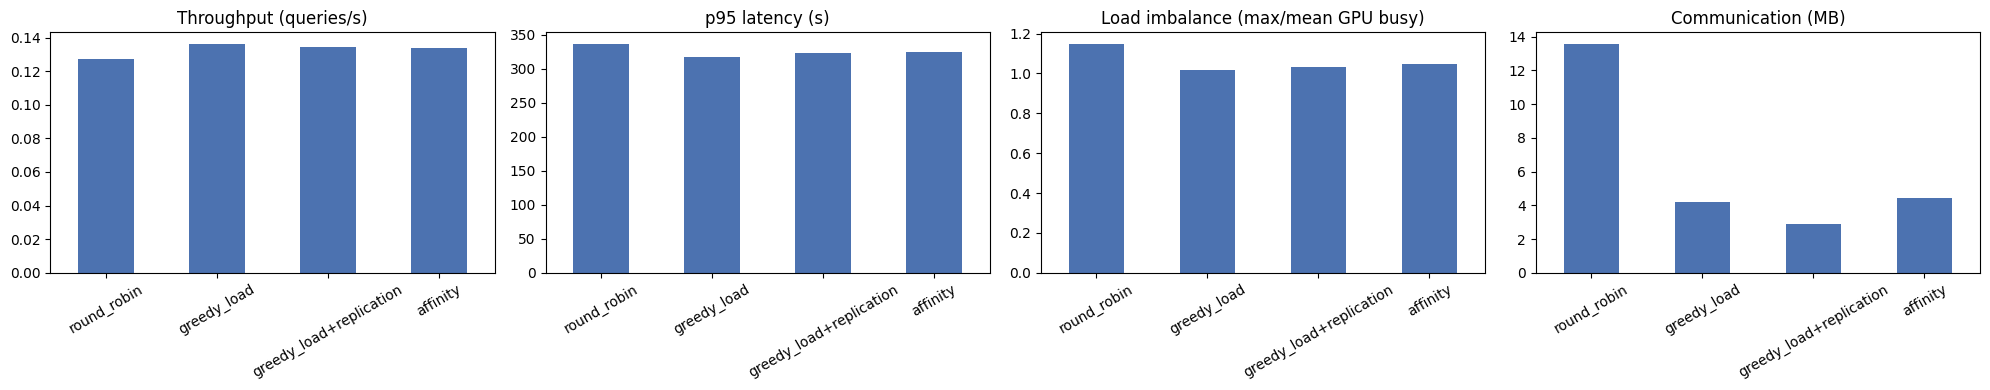

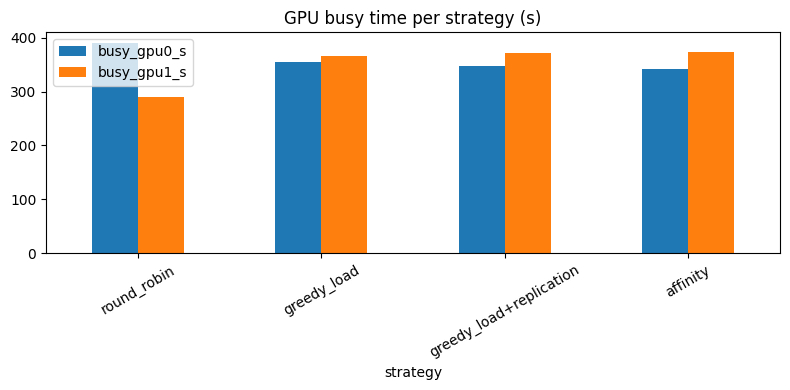

saved: ['coactivation.csv', 'comm_logs.csv', 'experiment_config.json', 'expert_costs.csv', 'gpu_busy.png', 'profile_log.csv', 'query_results.csv', 'run_logs.csv', 'strategy_comparison.png', 'strategy_summary.csv']


In [16]:
agg = summary_df.groupby("strategy", sort=False).mean(numeric_only=True)
metrics = [("throughput_qps", "Throughput (queries/s)"), ("p95_latency_s", "p95 latency (s)"),
           ("load_imbalance", "Load imbalance (max/mean GPU busy)"), ("comm_MB", "Communication (MB)")]
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (col, title) in zip(axes, metrics):
    agg[col].plot.bar(ax=ax, color="#4C72B0"); ax.set_title(title); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig(f"{OUT}/strategy_comparison.png", dpi=150); plt.show()

busy_cols = [f"busy_gpu{g}_s" for g in range(N_GPUS)]
agg[busy_cols].plot.bar(figsize=(8, 4), title="GPU busy time per strategy (s)")
plt.xticks(rotation=30); plt.tight_layout(); plt.savefig(f"{OUT}/gpu_busy.png", dpi=150); plt.show()

summary_df.to_csv(f"{OUT}/strategy_summary.csv", index=False)
runs_res.to_csv(f"{OUT}/query_results.csv", index=False)
runs_log.to_csv(f"{OUT}/run_logs.csv", index=False)
runs_comm.to_csv(f"{OUT}/comm_logs.csv", index=False)
json.dump({"workload": WORKLOAD, "placements": PLACEMENTS, "cap_gb": CAP_GB, "n_gpus": N_GPUS},
          open(f"{OUT}/experiment_config.json", "w"), indent=2)
print("saved:", sorted(os.listdir(OUT)))

## 12. Try your own document
Upload a PDF with *Add Data → Upload*, put its path below and write a question. It uses whichever placement was applied last.

In [17]:
# my = dict(qid="mine", question="Summarize this document.", doc="/kaggle/input/your-dataset/your_file.pdf")
# res, recs, comms = process_query(my)
# print(res["route"]); print(res["answer"]); display(pd.DataFrame(recs)); display(pd.DataFrame(comms))

## Files to download for the laptop simulator (`results/`)
- `expert_costs.csv`: per expert: memory, mean time, tokens/s, calls per query, expected load
- `coactivation.csv`: which experts hand work to each other
- `profile_log.csv`, `run_logs.csv`: every expert call (GPU, wait, time, tokens)
- `comm_logs.csv`: every hop between experts (GPUs, bytes, time)
- `query_results.csv`: route, latency and answer of every query
- `strategy_summary.csv`: the comparison table
- `experiment_config.json`: workload and placements, to replay them in the simulator

In [18]:
# ---- Manual placement experiment: E3 on both GPUs ----
MANUAL_PLACEMENT = {              # GPU0: E3 E7 E5 E6  |  GPU1: E3 E2 E0 E4
    "E3": [0, 1],
    "E7": [0], "E5": [0], "E6": [0],
    "E2": [1], "E0": [1], "E4": [1],
}
name, HEADROOM_GB = "manual_E3_replicated", 1.5

# memory check: keep at least 1.5 GB free per GPU for activations / KV cache / images
need  = [sum(MEM_GB[e] for e, gs in MANUAL_PLACEMENT.items() if g in gs) for g in range(N_GPUS)]
total = [torch.cuda.get_device_properties(g).total_memory / 1e9 for g in range(N_GPUS)]
for g in range(N_GPUS):
    print(f"GPU{g}: {need[g]:.2f} GB weights / {total[g]:.1f} GB -> {total[g]-need[g]:.2f} GB free")
assert all(total[g] - need[g] >= HEADROOM_GB for g in range(N_GPUS)), "not enough GPU memory for this placement"
assert set(EXPERTS) <= set(MANUAL_PLACEMENT), "every expert needs at least one GPU"
CAP_GB = max(CAP_GB, max(need) + 0.01)

# run it exactly like the other strategies
print(f"\n=== {name} ===")
apply_placement(MANUAL_PLACEMENT); warmup()
for rep in range(REPEATS):
    res, log, comm = run_workload(WORKLOAD, name, concurrent=True)
    for df in (res, log, comm): df["repeat"] = rep
    s = summarize_run(res, log, comm, name); s["repeat"] = rep
    summary.append(s); all_res.append(res); all_log.append(log); all_comm.append(comm)
    print(f"  throughput {s['throughput_qps']:.3f} q/s | mean latency {s['mean_latency_s']:.1f}s | "
          f"p95 {s['p95_latency_s']:.1f}s | imbalance {s['load_imbalance']:.2f} | comm {s['comm_MB']:.2f} MB")

PLACEMENTS[name] = MANUAL_PLACEMENT
summary_df = pd.DataFrame(summary)
runs_res, runs_log, runs_comm = pd.concat(all_res), pd.concat(all_log), pd.concat(all_comm)
display(summary_df.groupby("strategy").mean(numeric_only=True).round(3))

GPU0: 11.98 GB weights / 15.6 GB -> 3.66 GB free
GPU1: 13.17 GB weights / 15.6 GB -> 2.47 GB free

=== manual_E3_replicated ===


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

loaded E3 (General Reasoning) -> cuda:1 | 3.44 GB | 4s
GPU0: 12.37 GB allocated | experts: ['E3', 'E5', 'E6', 'E7']
GPU1: 13.45 GB allocated | experts: ['E0', 'E2', 'E3', 'E4']
warm-up done
  throughput 0.135 q/s | mean latency 194.0s | p95 331.1s | imbalance 1.03 | comm 8.52 MB


,queries,throughput_qps,mean_latency_s,p95_latency_s,mean_wait_s,load_imbalance,cross_gpu_hops,comm_MB,comm_ms,busy_gpu0_s,busy_gpu1_s,repeat
strategy,,,,,,,,,,,,
affinity,50.0,0.134,194.765,323.898,123.586,1.046,9.0,4.465,4.829,341.206,373.802,0.0
greedy_load,50.0,0.136,192.319,317.066,121.819,1.016,11.0,4.202,6.317,355.049,366.619,0.0
greedy_load+replication,50.0,0.134,195.325,323.019,123.901,1.033,7.0,2.892,2.886,347.996,372.021,0.0
manual_E3_replicated,50.0,0.135,193.990,331.093,123.000,1.026,10.0,8.524,80.287,368.932,349.976,0.0
round_robin,50.0,0.127,198.939,336.469,126.925,1.149,19.0,13.581,17.067,390.367,289.406,0.0
